# Desajuste por campo de estudio de graduados STEM en Ecuador
Harolt S. Farinango Palacios · Steven Paúl Rodríguez Guerrero · Kevin Andrés Erazo Yépez

Ejecutar de arriba hacia abajo con los cinco ZIP originales y `titulos2019.xlsx`, `ciuo.xlsx` directamente en `data/`, junto al notebook. No modificar los originales. Resultados condicionados a la regla normativa y a los registros evaluables; no son estimaciones causales ni predicciones de empleo futuro.

## 1. Configuración
Si faltan dependencias, ejecutar `%pip install -U pandas numpy scikit-learn xgboost matplotlib openpyxl joblib shap` y reiniciar el kernel. La búsqueda completa puede tardar según el equipo.


**Version 2:** AP replaces trapezoidal PR-AUC throughout. Outputs are isolated in `outputs_v2/`. Candidate household purge is a conservative sensitivity, not verified linkage. The 2025 data were already examined in version 1: this is a retrospective corrected evaluation, not a new untouched holdout. No model is selected using 2025. The original normative rule is retained, not independently validated for Ecuador.

In [1]:
# Uncomment once if dependencies are missing:
# %pip install pandas numpy scikit-learn xgboost matplotlib pyreadstat shap joblib openpyxl
from pathlib import Path
import zipfile, io, os
import hashlib, json, itertools, time, warnings, sys, re
from decimal import Decimal, InvalidOperation
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, joblib
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
                             confusion_matrix, brier_score_loss, auc)
from IPython.display import display
SEED=42
YEARS=list(range(2021,2026))
ROOT=Path('data'); OUT=Path('outputs_v2'); OUT.mkdir(exist_ok=True)
FIG=OUT/'figures'; FIG.mkdir(exist_ok=True)
assert ROOT.is_dir(), 'Coloque los siete archivos originales en data/'
# Candidate raw names: verify against annual dictionaries. Adjust per year below.
BASE={'degree':'p12b','education':'p10a','has_degree':'p12a','employed':'empleo',
      'occupation':'p41','weight':'fexp','age':'p03','sex':'p02','ethnicity':'p15',
      'marital':'p06','area':'area','province':'prov','psu':'upm','stratum':'estrato','income':'ingrl','activity':'condact'}
MAP={y:BASE.copy() for y in YEARS}
# Example: MAP[2021]['province']='...' (only after verifying dictionary)
# Explicit missing codes by semantic variable/year, according to dictionaries, not guessed.
MISSING={y:{} for y in YEARS}
# If documented stable cross-year household/person key exists, supply raw column names per year.
# Leave empty if not established; no independence claim will be made.
LINK_COLS={y:[] for y in YEARS}
# Optional documented unique person-period key for auditing duplicate interviews.
RECORD_COLS={y:['id_persona','mes'] for y in YEARS}
# Set only after reviewing the official annual dictionaries/rotation/weights.
DICTIONARIES_REVIEWED=True
DESIGN_REVIEWED=True  # True only if stratum and PSU names/meaning confirmed
# 2021 precision issue: compare float32 representations to catalogue codes.
ROUND_2021=True
BOOT=500; N_JOBS=min(4,os.cpu_count() or 1); MIN_GROUP=50
# Optional more detailed rule CSV: field,isco3,compatible (0/1),source; exhaustive for observed pairs.
ALT=ROOT/'alternative_rule.csv'
# Freeze config BEFORE examining 2025 outcomes. Never tune on 2025.
SOURCE='https://www.ecuadorencifras.gob.ec/enemdu-anual/'
if not DICTIONARIES_REVIEWED:
    print('Before official results, review annual dictionaries and set DICTIONARIES_REVIEWED=True.')


## 2. Inventory, catalogue validation and harmonisation
The original files are never modified. CNTP uses eight-digit codes; the manuscript defines level prefixes 3–6 and broad fields 05–07. Ambiguous 2021 codes are retained only when all possible catalogue candidates agree on eligibility, field and level; no specific degree is imputed. Verify the float32 mechanism against the source files: it is a sensitivity assumption, not an INEC-confirmed explanation.

In [2]:
def save(df,name):
    df.to_csv(OUT/f'{name}.csv',index=False)
    return df

def digest(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

def read_csv(p, **kw):
    for enc in ['utf-8-sig','latin-1']:
        try: return pd.read_csv(p,sep=None,engine='python',encoding=enc,dtype=str,**kw)
        except UnicodeDecodeError: pass
    raise ValueError(p)

def norm(v,width=None):
    if pd.isna(v) or str(v).strip() in ['', '.', 'NA','nan']: return None
    try:
        d=Decimal(str(v).strip().replace(',','.'))
        if not d.is_finite() or d!=d.to_integral_value() or d<0: return None
        s=str(int(d)); return s.zfill(width) if width else s
    except (InvalidOperation,ValueError): return None

def cat(path,width):
    if width==8:
        d=pd.read_excel(path,header=1,dtype=str)
        vals=set(d.loc[pd.to_numeric(d['Nivel'],errors='coerce').eq(9),'Código'].str.replace('.','',regex=False))
    else:
        d=pd.read_excel(path,dtype=str)
        vals=set(d.loc[pd.to_numeric(d['NIVEL'],errors='coerce').eq(4),'CODIGO'].str.zfill(4))
    assert vals and all(re.fullmatch(r'\d{'+str(width)+'}',v) for v in vals), (path, list(vals)[:10])
    return vals
files={}
for y in YEARS:
    candidates=[p for p in ROOT.glob('*.zip') if str(y) in p.name]
    if len(candidates)!=1: raise ValueError(f'{y}: expected one ZIP, found {candidates}')
    files[y]=candidates[0]
paths=list(files.values())+[ROOT/'titulos2019.xlsx',ROOT/'ciuo.xlsx']
if ALT.exists(): paths.append(ALT)
save(pd.DataFrame([{'file':str(p),'bytes':p.stat().st_size,'sha256':digest(p)} for p in paths]),'inventory')
CNTP=cat(paths[5],8); CIUO=cat(paths[6],4)
print('Catalogue counts:',len(CNTP),len(CIUO))
def level_field(s): return (s[0],s[1:3]) # manuscript CNTP structure; verify against catalogue
round_index={}
for s in CNTP: round_index.setdefault(int(np.float32(int(s))),[]).append(s)
@lru_cache(None)
def degree_info(raw,year):
    if pd.isna(raw): return (None,None,'invalid')
    candidates=round_index.get(int(raw),[]) if year==2021 and ROUND_2021 else []
    if not candidates and raw in CNTP: candidates=[raw]
    if not candidates: return (None,None,'not_in_catalogue')
    pairs={level_field(s) for s in candidates}
    if len(pairs)!=1: return (None,None,'ambiguous')
    level,field=next(iter(pairs)); return (level,field,'group_only' if len(candidates)>1 else 'unique')

def read_year(y,p):
    with zipfile.ZipFile(p) as z:
        member=next(n for n in z.namelist() if 'personas' in n.lower() and n.lower().endswith('.csv'))
        dictionary=next(n for n in z.namelist() if 'diccionario' in n.lower() and 'persona' in n.lower())
        dd=pd.read_excel(io.BytesIO(z.read(dictionary)),header=None)
        dd.to_csv(OUT/f'dictionary_{y}.csv',index=False,header=False)
        needed=set(MAP[y].values())|set(RECORD_COLS[y])|{'id_hogar','id_vivienda','mes'}
        with z.open(member) as f:
            d=pd.read_csv(f,sep=';',encoding='utf-8-sig',dtype=str,usecols=lambda c:c.strip().lower() in needed,na_values=[' ','  '],keep_default_na=True)
        print(y, len(d), member,flush=True)
    d.columns=d.columns.str.strip().str.lower()
    mapping=MAP[y]; required=list(mapping.values())+LINK_COLS[y]+RECORD_COLS[y]
    absent=[v for v in required if v not in d]
    if absent: raise ValueError(f'{y}: missing {absent}; check dictionary. Available: {list(d.columns)}')
    a=pd.DataFrame({k:d[v] for k,v in mapping.items()}); a['year']=y
    for k in mapping:
        if k in ['weight','psu','stratum','income']:
            a[k]=a[k].str.strip().replace('',None)
        else:
            lookup={v:norm(v,8 if k=='degree' else 4 if k=='occupation' else None) for v in a[k].dropna().unique()}
            a[k]=a[k].map(lookup).where(a[k].notna(),None)
        a[k]=a[k].where(~a[k].isin(MISSING[y].get(k,[])),None)
    a['weight']=pd.to_numeric(a.weight.str.replace(',','.',regex=False),errors='coerce')
    a['income']=pd.to_numeric(a.income.str.replace(',','.',regex=False),errors='coerce')
    a['income']=a.income.where(a.income.ne(999999) & np.isfinite(a.income))
    a['age']=pd.to_numeric(a.age,errors='coerce')
    for name,cols in [('link',LINK_COLS[y]),('record',RECORD_COLS[y])]:
        a[name]=d[cols[0]].fillna('').astype(str).str.cat(d[cols[1]].fillna('').astype(str),sep='|') if len(cols)==2 else d[cols].fillna('').astype(str).agg('|'.join,axis=1) if cols else None
        if cols and a[name].isna().all(): raise ValueError(f'{y}: incomplete {name} keys; review')
    # Identifiers include interview month; stripping suffix is only a candidate linkage, not verified identity.
    a['candidate_household']=d['id_hogar'].str.replace(r'\d{2}$','',regex=True)
    a['candidate_person']=d['id_persona'].str.replace(r'\d{2}$','',regex=True)
    return a

raw=pd.concat([read_year(y,p) for y,p in files.items()],ignore_index=True)
raw['row_id']=np.arange(len(raw))
# Audit cross-year candidate overlap; no pruning by undocumented identity.
linkaudit=[]
for y in YEARS[1:]:
    for k in ['candidate_household','candidate_person']:
        early=set(raw.loc[raw.year.lt(y),k].dropna()); later=set(raw.loc[raw.year.eq(y),k].dropna())
        linkaudit.append({'year':y,'key':k,'later_unique':len(later),'overlap':len(early & later)})
save(pd.DataFrame(linkaudit),'candidate_linkage_audit')
save(raw.groupby('year').size().rename('raw_records').reset_index(),'raw_counts')
# Duplicate keys are audited rather than automatically removed.
dup=raw.record.notna() & raw.duplicated(['year','record'],keep=False)
if dup.any():
    save(raw.loc[dup].groupby('year').size().rename('duplicate_records').reset_index(),'duplicate_audit')
    raise ValueError('Duplicate person-period keys: resolve against documented survey design before training.')
base=raw.loc[raw.education.isin(['9','10']) & raw.has_degree.eq('1') & raw.employed.eq('1')].copy()
base[['level','field','degree_status']]=pd.DataFrame([degree_info(v,y) for v,y in zip(base.degree,base.year)],index=base.index)
save(base.groupby(['year','degree_status'],dropna=False).size().rename('n').reset_index(),'degree_audit')
elig=base.loc[base.level.isin(list('3456')) & base.field.isin(['05','06','07'])].copy()
elig['isco3']=elig.occupation.where(elig.occupation.isin(CIUO)).str[:3]


Catalogue counts: 1707 438
2021 361790 BDDenemdu_personas_2021_anual.csv
2022 358096 BDDenemdu_personas_2022_anual.csv
2023 345174 BDDenemdu_personas_2023_anual.csv
2024 341394 BDDenemdu_personas_2024_anual.csv
2025 334786 BDDenemdu_personas_2025_anual.csv


## 3. Normative target and descriptive analysis
The compatibility sets below reproduce Montt (2015), Annex 2, p. 48, as adopted in the manuscript. ISCED-F 05 and 06 share the science/mathematics/computing set; 07 uses engineering. Military and groups 111, 961, 962 are excluded under the manuscript rule. Invalid or unknown occupations remain unclassified. [Source](https://doi.org/10.1787/5jrxm4dhv9r2-en).

In [3]:
SCI={211,212,213,226,231,232,233,251,252,311,313,314,321,331,351,352}
ENG={214,215,216,231,232,251,252,311,312,313,315,335,351,352,515,821,*range(711,714),*range(721,724),*range(731,733),*range(741,743),*range(751,755),*range(811,819),*range(831,836),*range(931,934)}
RULE={f:{str(x) for x in v} for f,v in [('05',SCI),('06',SCI),('07',ENG)]}
save(pd.DataFrame([(f,o) for f,os in RULE.items() for o in sorted(os)],columns=['field','compatible_isco3']),'montt_correspondence')
elig['exclusion']=np.select([elig.isco3.isna(),elig.isco3.fillna('').str.startswith('0'),elig.isco3.isin(['111','961','962'])],['invalid_occupation','military','excluded_group'],default='evaluable')
elig['y']=pd.Series([int(o not in RULE[f]) if e=='evaluable' else np.nan for f,o,e in zip(elig.field,elig.isco3,elig.exclusion)],index=elig.index)
save(elig.groupby(['year','exclusion']).size().rename('n').reset_index(),'exclusions')
audit=elig.groupby('year').agg(eligible=('y','size'),evaluable=('y','count')).reset_index()
audit['previous_eligible']=audit.year.map(dict(zip(YEARS,[4853,4956,4866,5030,5190])))
audit['previous_evaluable']=audit.year.map(dict(zip(YEARS,[4792,4891,4795,4946,5101])))
display(save(audit,'sample_audit'))
D=elig.loc[elig.y.notna()].copy(); D.y=D.y.astype(int)
if (~np.isfinite(D.weight) | (D.weight<=0)).any(): raise ValueError('Invalid annual survey weights: review before continuing.')
FEATURES=['age','sex','ethnicity','marital','area','province','field','education']
save(D.groupby('year')[FEATURES].agg(lambda s:s.isna().mean()).reset_index(),'missingness')
def describe(g):
    return pd.Series({'n':len(g),'mismatch_n':g.y.sum(),'unweighted_rate':g.y.mean(),'weighted_rate':np.average(g.y,weights=g.weight),'weight_sum':g.weight.sum()})
# Alternative rule must be explicitly documented and frozen before test.
D['y_alt']=np.nan
if ALT.exists():
    ar=read_csv(ALT); assert {'field','isco3','compatible','source'}<=set(ar.columns)
    assert not ar.duplicated(['field','isco3']).any() and ar.compatible.isin(['0','1']).all() and ar.source.str.strip().ne('').all()
    lookup={(f.zfill(2),o.zfill(3)):1-int(v) for f,o,v in zip(ar.field,ar.isco3,ar.compatible)}
    D['y_alt']=[lookup.get((f,o),np.nan) for f,o in zip(D.field,D.isco3)]
    save(D.assign(changed=D.y_alt.notna() & D.y_alt.ne(D.y),covered=D.y_alt.notna()).groupby('year').agg(n=('y','size'),covered=('covered','sum'),changed=('changed','sum')).reset_index(),'alternative_coverage')
else: print('Alternative detailed correspondence unavailable; this sensitivity will be skipped, not fabricated.')


,year,eligible,evaluable,previous_eligible,previous_evaluable
0,2021,4853,4792,4853,4792
1,2022,4956,4891,4956,4891
2,2023,4866,4795,4866,4795
3,2024,5030,4946,5030,4946
4,2025,5190,5101,5190,5101


Alternative detailed correspondence unavailable; this sensitivity will be skipped, not fabricated.


## 4. Temporal partition and model selection
Growing windows: 2021→2022 and 2021–2022→2023. For each configuration use mean weighted Average Precision (trapezoidal); also report average precision. Train the base estimator on 2021–2023, calibrate probabilities and choose the F1-maximising threshold on 2024, freeze before 2025. The same models are evaluated without weighting, without field, excluding 2021 and with a documented alternative label. No occupation or derived compatibility features enter X.

In [4]:
def partitions(data,years,valid,test=None,purge=False):
    tr=data[data.year.isin(years)].copy(); va=data[data.year.eq(valid)].copy(); te=data[data.year.eq(test)].copy() if test else None
    if all(LINK_COLS[y] for y in YEARS):
        if te is not None: va=va[~va.link.isin(te.link)]; tr=tr[~tr.link.isin(te.link)]
        tr=tr[~tr.link.isin(va.link)]
    if purge:
        if te is not None:
            va=va[~va.candidate_household.isin(te.candidate_household.dropna())]; tr=tr[~tr.candidate_household.isin(te.candidate_household.dropna())]
        tr=tr[~tr.candidate_household.isin(va.candidate_household.dropna())]
    for part in [tr,va]+([te] if te is not None else []):
        if part.y.nunique()!=2: raise ValueError('Partition lacks both classes')
    return tr,va,te
if not all(LINK_COLS[y] for y in YEARS): print('No verified cross-year linkage; independence cannot be asserted.')

def weights(d,weighted=True,normalize=False):
    if not weighted: return np.ones(len(d))
    w=d.weight.to_numpy(float)
    if normalize: w=w/d.groupby('year').weight.transform('sum').to_numpy()*len(d)/d.year.nunique()
    return w

def features(d,cols):
    X=d[cols].copy()
    for k in cols:
        if k!='age': X[k]=X[k].astype(object).where(X[k].notna(),np.nan)
    return X

def pipe(name,params,cols):
    cats=[x for x in cols if x!='age']; num=Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)),('scale',StandardScaler() if name=='LR' else 'passthrough')])
    catpipe=Pipeline([('impute',SimpleImputer(strategy='constant',fill_value='Missing')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    pre=ColumnTransformer([('num',num,['age']),('cat',catpipe,cats)])
    model={'LR':lambda:LogisticRegression(max_iter=2000,random_state=SEED,**params),'RF':lambda:RandomForestClassifier(random_state=SEED,n_jobs=N_JOBS,**params),'XGB':lambda:XGBClassifier(random_state=SEED,n_jobs=N_JOBS,eval_metric='logloss',subsample=.8,colsample_bytree=.8,**params)}[name]()
    return Pipeline([('pre',pre),('model',model)])
GRIDS={'LR':{'C':[.01,.1,1,10]},'RF':{'n_estimators':[300,600],'max_depth':[5,10,None],'min_samples_leaf':[5,20]},'XGB':{'max_depth':[2,4,6],'learning_rate':[.03,.1],'n_estimators':[200,500]}}
def average_precision(y,p,w):
    return average_precision_score(y,p,sample_weight=w)
def fit_model(name,params,tr,cols,weighted):
    m=pipe(name,params,cols); m.fit(features(tr,cols),tr.y,model__sample_weight=weights(tr,weighted,True)); return m

def select(data,years,cols,weighted,scenario):
    log=[]; best={}
    for name,grid in GRIDS.items():
        for params in ParameterGrid(grid):
            scores=[]; start=time.time()
            for i in range(1,len(years)):
                tr,va,_=partitions(data,years[:i],years[i],purge=scenario=="candidate_household_purge"); m=fit_model(name,params,tr,cols,weighted)
                scores.append(average_precision(va.y,m.predict_proba(features(va,cols))[:,1],weights(va)))
            log.append({'scenario':scenario,'model':name,'params':json.dumps(params),'mean_ap':np.mean(scores),'fold_scores':json.dumps(scores),'seconds':time.time()-start})
        choices=[r for r in log if r['model']==name]; best[name]=json.loads(max(choices,key=lambda r:r['mean_ap'])['params'])
    save(pd.DataFrame(log),f'grid_{scenario}'); return best

def metrics(y,p,w,t):
    tn,fp,fn,tp=confusion_matrix(y,p>=t,labels=[0,1],sample_weight=w).ravel()
    div=lambda a,b: a/b if b else np.nan
    sens=div(tp,tp+fn); spec=div(tn,tn+fp)
    both=len(np.unique(y))==2
    return {'roc_auc':roc_auc_score(y,p,sample_weight=w) if both else np.nan,'average_precision':average_precision(y,p,w) if both else np.nan,'positive_rate':np.average(y,weights=w),'sensitivity':sens,'specificity':spec,'precision':div(tp,tp+fp),'f1':div(2*tp,2*tp+fp+fn),'balanced_accuracy':(sens+spec)/2,'brier':brier_score_loss(y,p,sample_weight=w),'tn':tn,'fp':fp,'fn':fn,'tp':tp}

def logit(p):
    p=np.clip(p,1e-6,1-1e-6); return np.log(p/(1-p)).reshape(-1,1)
def threshold(y,p,w):
    pr,rc,ts=precision_recall_curve(y,p,sample_weight=w); f=np.divide(2*pr[:-1]*rc[:-1],pr[:-1]+rc[:-1],out=np.zeros(len(ts)),where=(pr[:-1]+rc[:-1])>0); return float(ts[np.argmax(f)])

# Separate fitting from final evaluation. Freeze all scenarios before examining test metrics.
scenarios={'main':(D,[2021,2022,2023],FEATURES,True),'unweighted':(D,[2021,2022,2023],FEATURES,False),'no_2021':(D,[2022,2023],FEATURES,True),'no_field':(D,[2021,2022,2023],[f for f in FEATURES if f!='field'],True)}
if D.y_alt.notna().any():
    altdata=D[D.y_alt.notna()].copy(); altdata.y=altdata.y_alt.astype(int); scenarios['alternative']=(altdata,[2021,2022,2023],FEATURES,True)
    common=D[D.y_alt.notna()].copy(); scenarios['main_common']=(common,[2021,2022,2023],FEATURES,True)
scenarios["candidate_household_purge"]=(D,[2021,2022,2023],FEATURES,True)
FROZEN={}; splitlog=[]; validation=[]
for scenario,(data,years,cols,weighted) in scenarios.items():
    print('Fitting',scenario,flush=True)
    tr,va,te=partitions(data,years,2024,2025,purge=scenario=="candidate_household_purge")
    splitlog.append({'scenario':scenario,'train':len(tr),'validation':len(va),'test':len(te),'verified_linkage':all(LINK_COLS[y] for y in YEARS),'candidate_purge':scenario=='candidate_household_purge','train_test_candidate_overlap':len(set(tr.candidate_household.dropna()) & set(te.candidate_household.dropna())),'validation_test_candidate_overlap':len(set(va.candidate_household.dropna()) & set(te.candidate_household.dropna()))})
    best=select(tr,years,cols,weighted,scenario); fitted={}
    for name in ['Constant',*GRIDS]:
        m=None if name=='Constant' else fit_model(name,best[name],tr,cols,weighted)
        prevalence=np.average(tr.y,weights=weights(tr,weighted,True))
        p=np.full(len(va),prevalence) if m is None else m.predict_proba(features(va,cols))[:,1]
        # Platt calibration for fitted classifiers; constant baseline remains training prevalence.
        cal=None if m is None else LogisticRegression(C=1e6,max_iter=1000).fit(logit(p),va.y,sample_weight=weights(va)/weights(va).mean())
        pc=p if cal is None else cal.predict_proba(logit(p))[:,1]
        t=threshold(va.y.to_numpy(),pc,weights(va))
        fitted[name]={'model':m,'calibrator':cal,'threshold':t,'prevalence':prevalence,'params':best.get(name,{})}
        validation.append({'scenario':scenario,'model':name,'threshold':t,**metrics(va.y,pc,weights(va),t)})
    FROZEN[scenario]=(fitted,cols,te,va)
save(pd.DataFrame(splitlog),'partitions'); save(pd.DataFrame(validation),'validation_metrics')
joblib.dump({k:(v[0],v[1]) for k,v in FROZEN.items()},OUT/'frozen_models.joblib')
(OUT/'config.json').write_text(json.dumps({'seed':SEED,'maps':MAP,'missing':MISSING,'links':LINK_COLS,'record_keys':RECORD_COLS,'round_2021':ROUND_2021,'design_reviewed':DESIGN_REVIEWED,'sklearn':sklearn.__version__,'xgboost':xgboost.__version__,'python':sys.version,'grids':GRIDS},indent=2))


No verified cross-year linkage; independence cannot be asserted.
Fitting main
Fitting unweighted
Fitting no_2021
Fitting no_field
Fitting candidate_household_purge


3271

## 5. Final test (2025)
Only execute once after all decisions are frozen. Compare each calibrated classifier at the frozen threshold and 0.5, with annual survey weights and unweighted. The output describes predictive performance relative to the normative rule, not causality.

,year,n,mismatch_n,unweighted_rate,weighted_rate,weight_sum
0,2021,4792.0,2010.0,0.419449,0.410741,167251.364513
1,2022,4891.0,1901.0,0.388673,0.356439,164308.874483
2,2023,4795.0,1881.0,0.392284,0.406761,176029.526883
3,2024,4946.0,1936.0,0.391427,0.403514,181860.960628
4,2025,5101.0,1980.0,0.388159,0.402817,174364.900852


,year,field,n,mismatch_n,unweighted_rate,weighted_rate,weight_sum
0,2021,05,482.0,280.0,0.580913,0.583679,16621.840997
1,2021,06,1120.0,543.0,0.484821,0.459353,42538.432679
2,2021,07,3190.0,1187.0,0.372100,0.365016,108091.090837
3,2022,05,411.0,218.0,0.530414,0.500824,16989.960542
4,2022,06,1107.0,512.0,0.462511,0.413918,40454.618387
5,2022,07,3373.0,1171.0,0.347169,0.311725,106864.295554
6,2023,05,420.0,231.0,0.550000,0.543035,14493.066059
7,2023,06,1097.0,515.0,0.469462,0.516239,48456.421062
8,2023,07,3278.0,1135.0,0.346248,0.342382,113080.039762
9,2024,05,441.0,244.0,0.553288,0.542792,13998.292724


,year,sex,n,mismatch_n,unweighted_rate,weighted_rate,weight_sum
0,2021,1,3553.0,1356.0,0.381649,0.365505,125905.998320
1,2021,2,1239.0,654.0,0.527845,0.548496,41345.366193
2,2022,1,3665.0,1283.0,0.350068,0.309486,125866.028240
3,2022,2,1226.0,618.0,0.504078,0.510171,38442.846243
4,2023,1,3574.0,1222.0,0.341914,0.331630,125032.776950
5,2023,2,1221.0,659.0,0.539722,0.590965,50996.749933
6,2024,1,3663.0,1237.0,0.337701,0.345638,131632.011898
7,2024,2,1283.0,699.0,0.544817,0.555184,50228.948730
8,2025,1,3769.0,1301.0,0.345184,0.348871,124277.679105
9,2025,2,1332.0,679.0,0.509760,0.536670,50087.221746


,year,province,n,mismatch_n,unweighted_rate,weighted_rate,weight_sum
0,2021,1,649.0,234.0,0.360555,0.378727,10722.637709
1,2021,10,127.0,61.0,0.480315,0.436958,3900.296449
2,2021,11,119.0,49.0,0.411765,0.435357,4832.428453
3,2021,12,22.0,12.0,0.545455,0.582278,2288.437220
4,2021,13,87.0,42.0,0.482759,0.415111,14341.164484
...,...,...,...,...,...,...,...
115,2025,5,144.0,72.0,0.500000,0.514186,6910.181471
116,2025,6,78.0,35.0,0.448718,0.444956,4467.959917
117,2025,7,330.0,139.0,0.421212,0.417897,4677.336549
118,2025,8,155.0,64.0,0.412903,0.396586,3426.461099


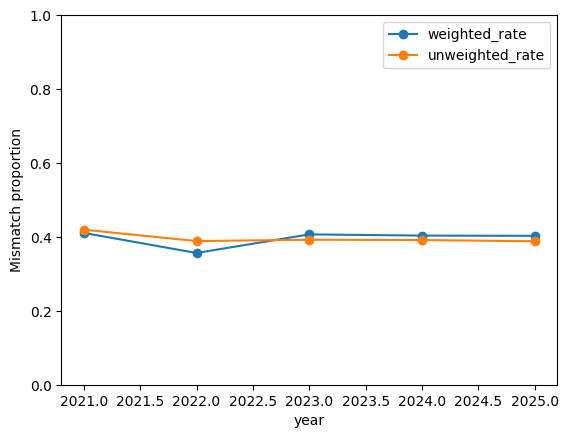

,model,threshold,raw_brier,roc_auc,average_precision,positive_rate,sensitivity,specificity,precision,f1,balanced_accuracy,brier,tn,fp,fn,tp
0,Constant,0.391314,0.240688,0.500000,0.402817,0.402817,1.000000,0.000000,0.402817,0.574298,0.500000,0.240688,0.000000,104127.690841,0.000000,70237.210011
4,LR,0.249871,0.223397,0.652199,0.565753,0.402817,0.923553,0.118837,0.414170,0.571879,0.521195,0.223308,12374.221589,91753.469252,5369.415915,64867.794096
8,RF,0.356315,0.225091,0.643433,0.557882,0.402817,0.697403,0.488699,0.479178,0.568053,0.593051,0.225899,50887.093048,53240.597793,21253.575344,48983.634666
12,XGB,0.279486,0.226133,0.638080,0.567285,0.402817,0.888012,0.210781,0.431484,0.580772,0.549396,0.225275,21948.164445,82179.526397,7865.752300,62371.457711


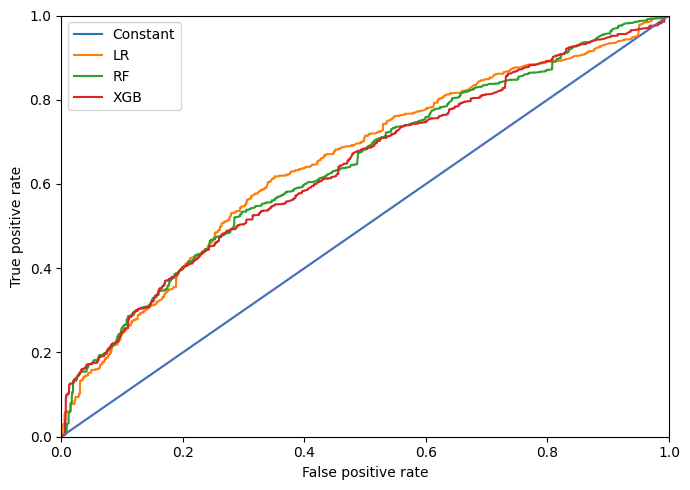

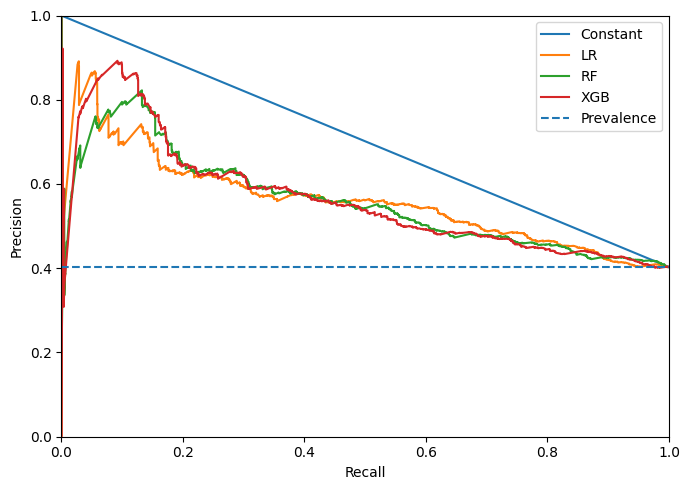

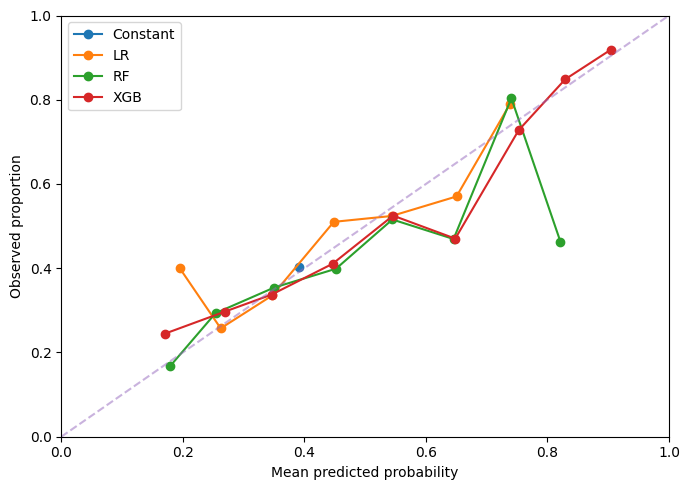

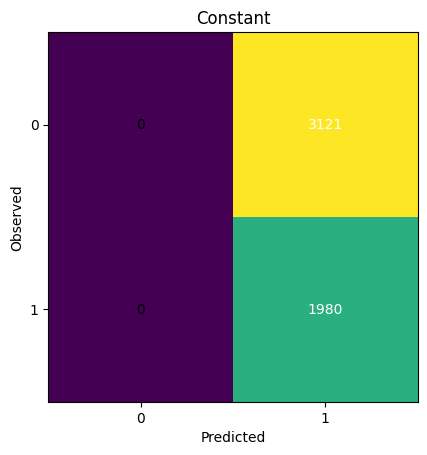

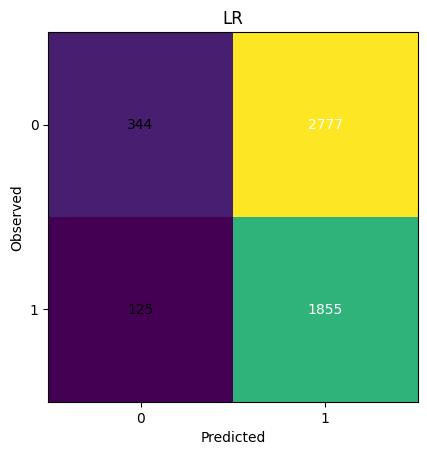

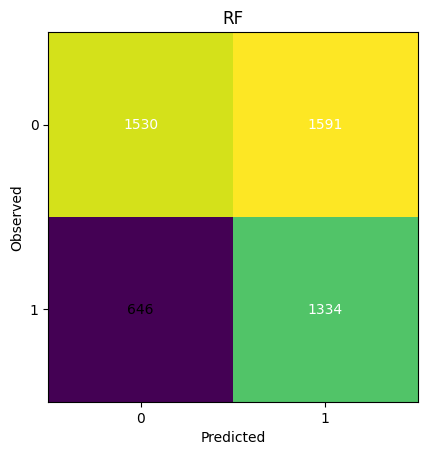

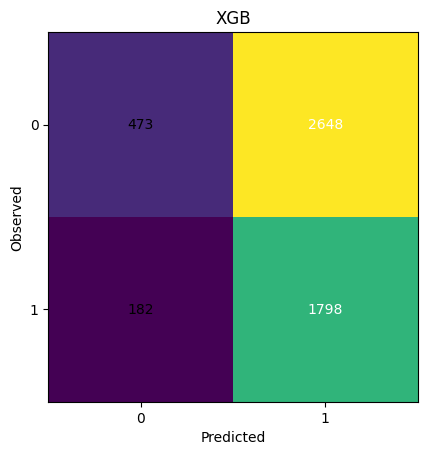

In [5]:
for keys,name in [(['year'],'annual_mismatch'),(['year','field'],'mismatch_by_field'),(['year','sex'],'mismatch_by_sex'),(['year','province'],'mismatch_by_province')]:
    tab=D.groupby(keys,dropna=False)[['y','weight']].apply(describe).reset_index(); display(save(tab,name))
annual=pd.read_csv(OUT/'annual_mismatch.csv'); ax=annual.plot(x='year',y=['weighted_rate','unweighted_rate'],marker='o',ylim=(0,1),ylabel='Mismatch proportion'); ax.figure.savefig(FIG/'annual_mismatch.png',dpi=250,bbox_inches='tight'); plt.show()

def predict(f,d,cols):
    p=np.full(len(d),f['prevalence']) if f['model'] is None else f['model'].predict_proba(features(d,cols))[:,1]
    return p,p if f['calibrator'] is None else f['calibrator'].predict_proba(logit(p))[:,1]
rows=[]; preds={}; subgroup=[]
for scenario,(fitted,cols,te,va) in FROZEN.items():
    for name,f in fitted.items():
        rawp,p=predict(f,te,cols); preds[scenario,name]=p
        for mode in [True,False]:
            w=weights(te,mode)
            for label,t in [('validation_F1',f['threshold']),('0.5',.5)]:
                rows.append({'scenario':scenario,'model':name,'weighted':mode,'threshold_type':label,'threshold':t,'raw_brier':brier_score_loss(te.y,rawp,sample_weight=w),**metrics(te.y,p,w,t)})
        if scenario=='main':
            for key in ['sex','field']:
                for value,g in te.groupby(key,dropna=False):
                    if len(g)<MIN_GROUP or g.y.nunique()<2: continue
                    _,pg=predict(f,g,cols); subgroup.append({'model':name,'group':key,'value':value,'n':len(g),**metrics(g.y,pg,weights(g),f['threshold'])})
            for year,part in [(2024,va),(2025,te)]:
                _,pp=predict(f,part,cols); subgroup.append({'model':name,'group':'year (2024 calibration; 2025 test)','value':year,'n':len(part),**metrics(part.y,pp,weights(part),f['threshold'])})
results=save(pd.DataFrame(rows),'test_metrics'); save(pd.DataFrame(subgroup),'subgroups')
main=results.query("scenario=='main' and weighted==True and threshold_type=='validation_F1'")
display(main.drop(columns=['scenario','weighted','threshold_type']))
fitted,cols,te,va=FROZEN['main']; y=te.y.to_numpy(); w=weights(te)
calrows=[]
for chart in ['roc','pr','calibration']:
    fig,ax=plt.subplots(figsize=(7,5))
    for name,f in fitted.items():
        p=preds['main',name]
        if chart=='roc': a,b,_=roc_curve(y,p,sample_weight=w); ax.plot(a,b,label=name)
        elif chart=='pr': b,a,_=precision_recall_curve(y,p,sample_weight=w); ax.plot(a,b,label=name)
        else:
            bins=np.minimum((p*10).astype(int),9)
            points=[(np.average(p[bins==i],weights=w[bins==i]),np.average(y[bins==i],weights=w[bins==i]),int((bins==i).sum())) for i in np.unique(bins)]
            ax.plot([a for a,b,n in points],[b for a,b,n in points],marker='o',label=name)
            calrows.extend({'model':name,'predicted':a,'observed':b,'n':n} for a,b,n in points)
    if chart in ['roc','calibration']: ax.plot([0,1],[0,1],'--',alpha=.5)
    else: ax.axhline(np.average(y,weights=w),linestyle='--',label='Prevalence')
    ax.set(xlim=(0,1),ylim=(0,1),xlabel={'roc':'False positive rate','pr':'Recall','calibration':'Mean predicted probability'}[chart],ylabel={'roc':'True positive rate','pr':'Precision','calibration':'Observed proportion'}[chart]); ax.legend(); fig.tight_layout(); fig.savefig(FIG/f'{chart}.png',dpi=250); plt.show()
save(pd.DataFrame(calrows),'calibration_bins')
for name,f in fitted.items():
    cm=confusion_matrix(y,preds['main',name]>=f['threshold'],labels=[0,1]); fig,ax=plt.subplots(); ax.imshow(cm); ax.set(xticks=[0,1],yticks=[0,1],xlabel='Predicted',ylabel='Observed',title=name)
    for i,j in itertools.product(range(2),repeat=2): ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    fig.savefig(FIG/f'confusion_{name}.png',dpi=250,bbox_inches='tight'); plt.show()


## 6. Uncertainty and paired differences
Approximate stratified cluster bootstrap of fixed test predictions, not model refitting. Sample PSUs with replacement within strata, preserving survey weights and using the same replicate for all models. Single-PSU strata are retained with multiplier one and documented; intervals may underestimate uncertainty. If the design cannot be established, do not substitute individual bootstrap.

In [6]:
if DESIGN_REVIEWED and te[['psu','stratum']].notna().all().all():
    rng=np.random.default_rng(SEED); groups={s:[np.flatnonzero((te.stratum==s)&(te.psu==p)) for p in g.psu.unique()] for s,g in te.groupby('stratum')}
    single=sum(len(v)==1 for v in groups.values()); print('Single-PSU strata:',single)
    bootrows=[]; failures=0
    for r in range(BOOT):
        ix=np.concatenate([np.concatenate([g[j] for j in rng.integers(0,len(g),len(g))]) for g in groups.values()])
        if len(np.unique(y[ix]))<2: failures+=1; continue
        rep={name:metrics(y[ix],preds['main',name][ix],w[ix],f['threshold']) for name,f in fitted.items()}
        for name,met in rep.items():
            bootrows.append({'replicate':r,'model':name,**met})
        for a,b in itertools.combinations(fitted,2):
            bootrows.append({'replicate':r,'model':f'{a} minus {b}',**{k:rep[a][k]-rep[b][k] for k in ['roc_auc','average_precision','f1','balanced_accuracy','brier']}})
        bootrows.append({'replicate':r,'model':'weighted_prevalence','positive_rate':np.average(y[ix],weights=w[ix])})
    bootdf=save(pd.DataFrame(bootrows),'bootstrap_replicates')
    if len(bootdf):
        ci=bootdf.drop(columns='replicate').groupby('model').quantile([.025,.975]).reset_index(); display(save(ci,'bootstrap_intervals'))
    save(pd.DataFrame([{'requested':BOOT,'failed':failures,'single_psu_strata':single}]),'bootstrap_audit')
else: print('Design not verified or missing PSU/stratum: no uncertainty intervals reported.')


Single-PSU strata: 14


,model,level_1,roc_auc,average_precision,positive_rate,sensitivity,specificity,precision,f1,balanced_accuracy,brier,tn,fp,fn,tp
0,Constant,0.025,0.500000,0.364248,0.364248,1.000000,0.000000,0.364248,0.533991,0.500000,0.232304,0.000000,96076.796925,0.000000,60567.376858
1,Constant,0.975,0.500000,0.435475,0.435475,1.000000,0.000000,0.435475,0.606733,0.500000,0.247787,0.000000,113380.541351,0.000000,78177.176877
2,Constant minus LR,0.025,-0.196191,-0.222510,NaN,NaN,NaN,NaN,-0.015146,-0.043223,0.003860,NaN,NaN,NaN,NaN
3,Constant minus LR,0.975,-0.091472,-0.084034,NaN,NaN,NaN,NaN,0.027642,0.007834,0.030016,NaN,NaN,NaN,NaN
4,Constant minus RF,0.025,-0.186113,-0.215442,NaN,NaN,NaN,NaN,-0.022828,-0.123084,0.001274,NaN,NaN,NaN,NaN
5,Constant minus RF,0.975,-0.095429,-0.089753,NaN,NaN,NaN,NaN,0.039727,-0.058427,0.028189,NaN,NaN,NaN,NaN
6,Constant minus XGB,0.025,-0.182721,-0.227326,NaN,NaN,NaN,NaN,-0.022055,-0.071037,0.000603,NaN,NaN,NaN,NaN
7,Constant minus XGB,0.975,-0.086766,-0.084840,NaN,NaN,NaN,NaN,0.010203,-0.027567,0.029795,NaN,NaN,NaN,NaN
8,LR,0.025,0.591472,0.469138,0.364248,0.872764,0.095349,0.373530,0.528976,0.492166,0.212482,9823.588228,84520.530129,2698.427608,56292.911288
9,LR,0.975,0.696191,0.648074,0.435475,0.960542,0.140236,0.448947,0.605674,0.543223,0.236989,14781.804757,99953.515800,9307.764279,72358.577296


## 7. Interpretation and sensitivity
Permutation importance uses weighted Average Precision loss on fixed test predictions, with repeated random permutations of original variables. Regression coefficients refer to encoded features. SHAP is optional for the tree models and explains raw model output, not causal effects or calibrated probabilities. Sensitivity comparisons are descriptive; the alternative label comparison includes a common-coverage main model.

,model,variable,mean_ap_drop,sd
1,LR,sex,0.075491,0.023846
6,LR,field,0.036538,0.010152
5,LR,province,0.030947,0.008786
4,LR,area,0.021265,0.008188
3,LR,marital,0.007448,0.002764
7,LR,education,0.004664,0.003717
0,LR,age,0.002169,0.010119
2,LR,ethnicity,-0.000401,0.002207
14,RF,field,0.053641,0.012960
9,RF,sex,0.041109,0.013949


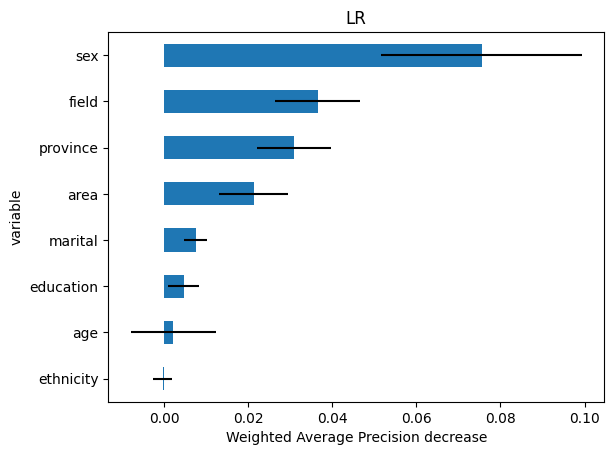

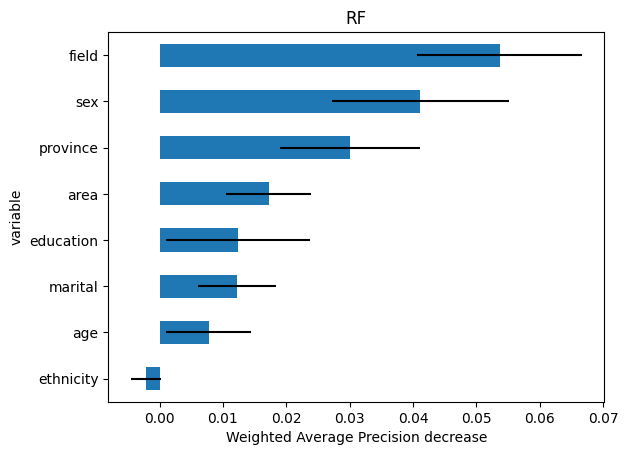

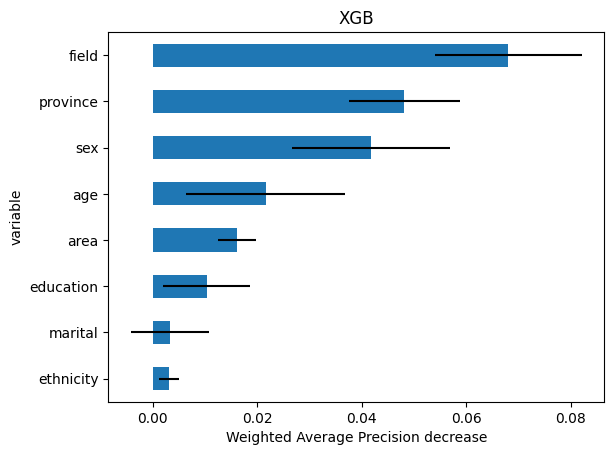

average_precision                                           \
scenario candidate_household_purge      main   no_2021  no_field unweighted   
model                                                                         
Constant                  0.402817  0.402817  0.402817  0.402817   0.402817   
LR                        0.570209  0.565753  0.561840  0.561583   0.569852   
RF                        0.556148  0.557882  0.542932  0.533981   0.574619   
XGB                       0.550676  0.567285  0.553679  0.535322   0.586277   

                           roc_auc                                           \
scenario candidate_household_purge      main   no_2021  no_field unweighted   
model                                                                         
Constant                  0.500000  0.500000  0.500000  0.500000   0.500000   
LR                        0.650210  0.652199  0.649501  0.636547   0.661553   
RF                        0.635466  0.643433  0.638305  0.615055   0.647625   
XGB                       0.639853  0.638080  0.644661  0.615440   0.663756   

                                f1                                           \
scenario candidate_household_purge      main   no_2021  no_field unweighted   
model                                                                         
Constant                  0.574298  0.574298  0.574298  0.574298   0.574298   
LR                        0.572261  0.571879  0.572352  0.574884   0.583785   
RF                        0.562947  0.568053  0.581488  0.571239   0.572289   
XGB                       0.568221  0.580772  0.579010  0.572917   0.587348   

                             brier                                           
scenario candidate_household_purge      main   no_2021  no_field unweighted  
model                                                                        
Constant                  0.240596  0.240688  0.241006  0.240688   0.240563  
LR                        0.223463  0.223308  0.224139  0.227505   0.221633  
RF                        0.225309  0.225899  0.227264  0.230897   0.222872  
XGB                       0.225536  0.225275  0.225851  0.229423   0.219247

Outputs: /home/paul/Documents/SEMESTRE 8/PA - TALLER DE COMUNICACION CIENTIFICA/FINAL PROJECT REPOSITORY/outputs_v2


In [7]:
rng=np.random.default_rng(SEED); imp=[]
for name,f in fitted.items():
    if f['model'] is None: continue
    baseline=average_precision(y,preds['main',name],w)
    for col in cols:
        drops=[]
        for r in range(10):
            shuffled=te.copy(); shuffled[col]=rng.permutation(te[col].to_numpy()); _,p=predict(f,shuffled,cols); drops.append(baseline-average_precision(y,p,w))
        imp.append({'model':name,'variable':col,'mean_ap_drop':np.mean(drops),'sd':np.std(drops,ddof=1)})
importance=save(pd.DataFrame(imp),'permutation_importance'); display(importance.sort_values(['model','mean_ap_drop'],ascending=[True,False]))
for name,g in importance.groupby('model'):
    ax=g.sort_values('mean_ap_drop').plot.barh(x='variable',y='mean_ap_drop',xerr='sd',legend=False,title=name); ax.set_xlabel('Weighted Average Precision decrease'); ax.figure.savefig(FIG/f'importance_{name}.png',dpi=250,bbox_inches='tight'); plt.show()
lr=fitted['LR']['model']; save(pd.DataFrame({'feature':lr.named_steps['pre'].get_feature_names_out(),'coefficient':lr.named_steps['model'].coef_[0]}),'logistic_coefficients')
shap_status=[]
for name in ['RF','XGB']:
    try:
        import shap
        m=fitted[name]['model']; X=m.named_steps['pre'].transform(features(te.sample(min(500,len(te)),random_state=SEED),cols)); names=m.named_steps['pre'].get_feature_names_out()
        sv=shap.TreeExplainer(m.named_steps['model']).shap_values(X)
        if isinstance(sv,list): sv=sv[1]
        if np.ndim(sv)==3: sv=sv[:,:,1]
        assert sv.shape==X.shape
        save(pd.DataFrame({'feature':names,'mean_abs_shap':np.abs(sv).mean(axis=0)}),'shap_'+name)
        shap_status.append({'model':name,'status':'ok'})
    except Exception as e: shap_status.append({'model':name,'status':repr(e)})
save(pd.DataFrame(shap_status),'shap_status')
sensitivity=results.query("weighted==True and threshold_type=='validation_F1'").pivot(index='model',columns='scenario',values=['average_precision','roc_auc','f1','brier']); sensitivity.to_csv(OUT/'sensitivity_comparison.csv'); display(sensitivity)
print('Outputs:',OUT.resolve())

# Export compact publication table
main[['model','roc_auc','average_precision','precision','sensitivity','specificity','f1','balanced_accuracy','brier']].to_csv(OUT/'paper_model_comparison.csv',index=False)


## 8. Additional descriptive analysis and domain uncertainty
Income comparisons are nominal, within year, and descriptive, not causal wage penalties. Specific titles are reported only when uniquely resolved; small groups are not interpreted. The candidate household sensitivity does not establish identity.

Degree catalogue columns: ['Código', 'Descripción', 'Nivel', ' CNTP V1', 'Descripción (Nomenclatura)']


/tmp/ipykernel_36613/3732564392.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table=D.groupby(keys,observed=True,dropna=True).apply(lambda g:describe(g[['y','weight']])).reset_index()
/tmp/ipykernel_36613/3732564392.py:15: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  table=D.groupby(keys,observed=True,dropna=True).apply(lambda g:describe(g[['y','weight']])).reset_index()


,year,y,n,income_valid_n,income_missing_n,income_mean_nominal_usd,income_median_nominal_usd,activity_valid_n,adequate_rate,underemployment_rate
0,2021,0,2782,2627,155,1064.413460,865.0,2782,0.753782,0.132171
1,2021,1,2010,1741,269,1025.188241,720.0,2010,0.656458,0.169141
2,2022,0,2990,2923,67,1077.793294,900.0,2990,0.815491,0.103603
3,2022,1,1901,1736,165,1093.237192,765.0,1901,0.675605,0.176061
4,2023,0,2914,2850,64,1100.262608,900.0,2914,0.842028,0.093745
5,2023,1,1881,1696,185,927.981995,630.0,1881,0.662102,0.149204
6,2024,0,3010,2950,60,1074.954772,876.0,3010,0.807917,0.114587
7,2024,1,1936,1761,175,887.685546,630.0,1936,0.642698,0.182097
8,2025,0,3121,3049,72,1087.652075,898.0,3121,0.824867,0.097349
9,2025,1,1980,1811,169,862.797568,663.0,1980,0.613623,0.185806


,year,occupation,n,weight_sum,share_among_mismatched,description
141,2021,5223,170,6220.337844,0.090547,ASISTENTES DE VENTA DE TIENDAS Y ALMACENES
139,2021,5221,148,3862.382821,0.056223,COMERCIANTES DE TIENDAS
46,2021,2330,91,3155.348688,0.045931,PROFESORES DE ENSEÑANZA SECUNDARIA
90,2021,3322,80,2963.216452,0.043135,REPRESENTANTES COMERCIALES
355,2022,5223,151,4498.940660,0.076818,ASISTENTES DE VENTA DE TIENDAS Y ALMACENES
353,2022,5221,137,4183.119420,0.071426,COMERCIANTES DE TIENDAS
257,2022,2330,93,3099.345916,0.052920,PROFESORES DE ENSEÑANZA SECUNDARIA
302,2022,3322,88,2785.705007,0.047565,REPRESENTANTES COMERCIALES
265,2022,2359,61,1983.306517,0.033864,PROFESIONALES DE LA ENSEÑANZA NO CLASIFICADOS ...
555,2023,5223,160,5508.972446,0.076939,ASISTENTES DE VENTA DE TIENDAS Y ALMACENES


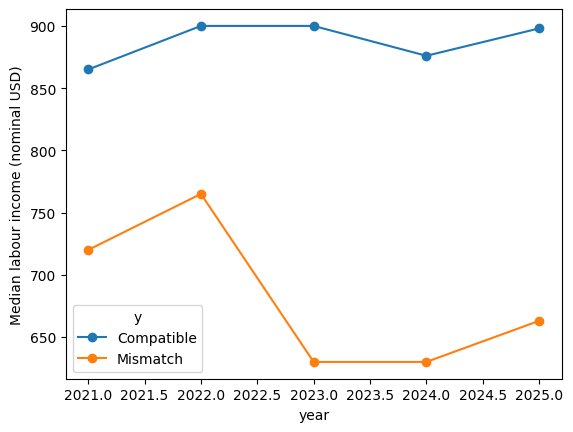

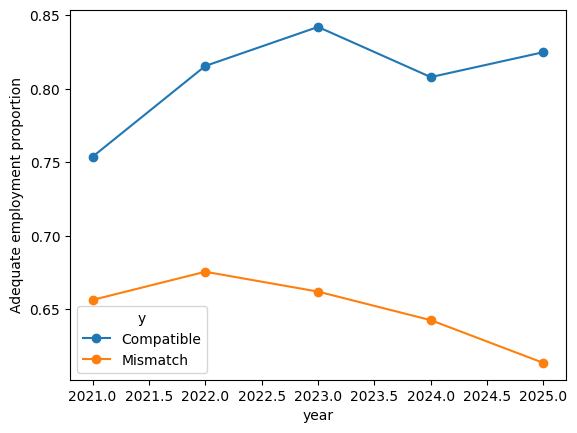

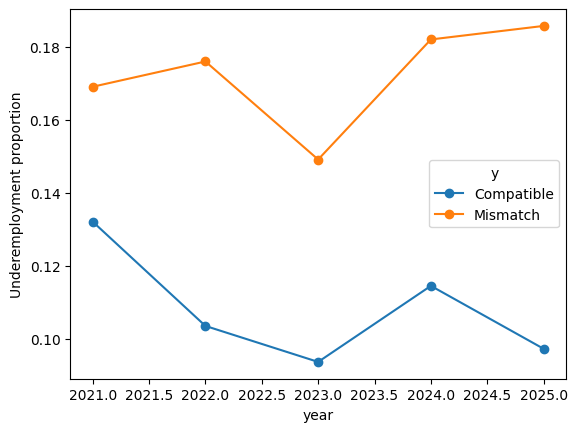

,year,domain,value,n,rate,lower,upper,replicates,single_psu_strata
0,2021,all,all,4792,0.410741,0.385831,0.434695,500,0
1,2021,field,05,482,0.583679,0.508562,0.657730,500,0
2,2021,field,06,1120,0.459353,0.413072,0.507715,500,0
3,2021,field,07,3190,0.365016,0.333544,0.396374,500,0
4,2021,sex,1,3553,0.365505,0.336702,0.393319,500,0
5,2021,sex,2,1239,0.548496,0.502689,0.594716,500,0
6,2021,age_group,<=24,138,0.478544,0.327353,0.615771,500,0
7,2021,age_group,25-34,1916,0.408396,0.367335,0.449122,500,0
8,2021,age_group,35-44,1292,0.383663,0.338030,0.424907,500,0
9,2021,age_group,45-54,721,0.439215,0.375746,0.497984,500,0


In [8]:
# Additional descriptive analyses: never feed these variables to the classifiers.
# INEC: condact 1 adequate employment; 2/3 underemployment; 999999 nonresponse.
# https://anda.inec.gob.ec/anda5/index.php/catalog/1270/variable/F11/V955?name=condact
# https://www.ecuadorencifras.gob.ec/documentos/web-inec/EMPLEO/2025/abril/202504_Guia_de_usuario_BDD_ENEMDU.pdf
D['age_group']=pd.cut(D.age,[0,24,34,44,54,64,np.inf],labels=['<=24','25-34','35-44','45-54','55-64','65+'])
D['degree_exact']=D.degree.where(D.degree_status.eq('unique'))
# For 2021, recover unique catalogue code rather than reporting rounded raw value.
mask=D.year.eq(2021)&D.degree_status.eq('unique')
D.loc[mask,'degree_exact']=D.loc[mask,'degree'].map(lambda x: (round_index.get(int(x),[]) or [x])[0])
deg=pd.read_excel(ROOT/'titulos2019.xlsx',header=1,dtype=str)
print('Degree catalogue columns:',deg.columns.tolist())
occ=pd.read_excel(ROOT/'ciuo.xlsx',dtype=str)
occ_labels=occ.loc[pd.to_numeric(occ.NIVEL,errors='coerce').eq(4)].assign(code=lambda x:x.CODIGO.str.zfill(4)).drop_duplicates('code').set_index('code').DESCRIPCION.to_dict()
for keys,name in [(['year','age_group'],'mismatch_by_age'),(['year','degree_exact'],'mismatch_by_degree')]:
    table=D.groupby(keys,observed=True,dropna=True).apply(lambda g:describe(g[['y','weight']])).reset_index()
    table['reportable']=table.n.ge(MIN_GROUP); table.loc[~table.reportable,['weighted_rate','unweighted_rate']]=np.nan
    save(table,name)
save(D.groupby('year').degree_exact.agg(n='size',exact='count').reset_index(),'exact_degree_coverage')
def weighted_median(x,w):
    order=np.argsort(x); x=np.asarray(x)[order]; w=np.asarray(w)[order]; return x[np.searchsorted(np.cumsum(w),w.sum()/2)]
rows=[]
for (year,target),g in D.groupby(['year','y']):
    valid=g[g.income.notna()]; a=g[g.activity.isin(list('123456'))]
    rows.append({'year':year,'y':target,'n':len(g),'income_valid_n':len(valid),'income_missing_n':len(g)-len(valid),'income_mean_nominal_usd':np.average(valid.income,weights=valid.weight) if len(valid) else np.nan,'income_median_nominal_usd':weighted_median(valid.income,valid.weight) if len(valid) else np.nan,'activity_valid_n':len(a),'adequate_rate':np.average(a.activity.eq('1'),weights=a.weight) if len(a) else np.nan,'underemployment_rate':np.average(a.activity.isin(['2','3']),weights=a.weight) if len(a) else np.nan})
economic=save(pd.DataFrame(rows),'income_and_employment'); display(economic)
# Negative incomes retained if recorded; separate audit, not silently recoded.
save(D.groupby('year').income.agg(n='count',minimum='min',maximum='max',negative=lambda x:x.lt(0).sum(),zero=lambda x:x.eq(0).sum()).reset_index(),'income_audit')
m=D[D.y.eq(1)].copy(); top=m.groupby(['year','occupation']).agg(n=('y','size'),weight_sum=('weight','sum')).reset_index(); top['share_among_mismatched']=top.weight_sum/top.groupby('year').weight_sum.transform('sum'); top['description']=top.occupation.map(occ_labels); top=top.sort_values(['year','weight_sum'],ascending=[True,False]); save(top,'mismatched_occupations'); display(top[top.n.ge(MIN_GROUP)].groupby('year').head(10))
for var,label in [('income_median_nominal_usd','Median labour income (nominal USD)'),('adequate_rate','Adequate employment proportion'),('underemployment_rate','Underemployment proportion')]:
    ax=economic.pivot(index='year',columns='y',values=var).rename(columns={0:'Compatible',1:'Mismatch'}).plot(marker='o',ylabel=label); ax.figure.savefig(FIG/f'{var}.png',dpi=250,bbox_inches='tight'); plt.show()
# Approximate domain intervals: sample PSUs from the full annual raw survey frame,
# including PSUs with zero eligible cases. Fixed labels; not official design estimates.
intervals=[]
if DESIGN_REVIEWED:
    for year in YEARS:
        frame=raw.loc[raw.year.eq(year),['stratum','psu']].dropna().drop_duplicates()
        g=D[D.year.eq(year)].copy()
        if not g[['stratum','psu']].notna().all().all(): continue
        frame['key']=list(zip(frame.stratum,frame.psu)); g['key']=list(zip(g.stratum,g.psu))
        keys=list(frame.key); key_index={k:i for i,k in enumerate(keys)}; gi=np.array([key_index[k] for k in g.key]); strata=[np.array([key_index[k] for k in part.key]) for _,part in frame.groupby('stratum')]
        rng=np.random.default_rng(SEED+year)
        mult=np.zeros((BOOT,len(keys)),dtype=np.int16)
        for ix in strata: mult[:,ix]=rng.multinomial(len(ix),np.full(len(ix),1/len(ix)),size=BOOT)
        for domain in ['all','field','sex','age_group']:
            groups=[('all',g)] if domain=='all' else g.groupby(domain,observed=True,dropna=True)
            for value,h in groups:
                if len(h)<MIN_GROUP or h.y.nunique()<2: continue
                idx=np.array([key_index[k] for k in h.key]); den=np.bincount(idx,weights=h.weight,minlength=len(keys)); num=np.bincount(idx,weights=h.weight*h.y,minlength=len(keys)); a=mult@num; b=mult@den; rates=a[b>0]/b[b>0]
                if len(rates): intervals.append({'year':year,'domain':domain,'value':str(value),'n':len(h),'rate':num.sum()/den.sum(),'lower':np.quantile(rates,.025),'upper':np.quantile(rates,.975),'replicates':len(rates),'single_psu_strata':sum(len(ix)==1 for ix in strata)})
save(pd.DataFrame(intervals),'descriptive_intervals'); display(pd.DataFrame(intervals))


## 9. Reporting checklist
Use the exported audit, descriptive rates, test metrics, uncertainty, variable importance and sensitivity tables in the paper. The alternative rule is optional and is skipped if no independently documented alternative is supplied. The candidate linkage audit does not establish longitudinal identity; temporal separation is not a guarantee of independence. Cluster bootstrap is an approximate conditional analysis, not a full survey-design variance estimator. No causal claims.
